<a href="https://colab.research.google.com/github/purnaa-l/AirVana-ML-Models/blob/main/Apiori/Apiori_on_AQI_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules
df = pd.read_csv("AirQualityData.csv")
print("Columns:", df.columns)
columns_to_use = [
    "CO(GT)", "NOx(GT)", "NO2(GT)", "O3(GT)", "SO2(GT)",
    "PM2.5", "PM10", "Temperature", "Humidity", "Pressure",
    "AirQualityIndex"
]
data = df[columns_to_use].copy()
binned_data = pd.DataFrame()
for col in data.columns:
    binned_data[col] = pd.qcut(data[col].rank(method='first'), 3, labels=["Low", "Medium", "High"])
transactions = pd.get_dummies(binned_data)
frequent_itemsets = apriori(transactions, min_support=0.1, use_colnames=True)
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)
rules = rules.sort_values(["confidence", "lift"], ascending=False)
co_aqi_rules = rules[
    (rules['antecedents'].apply(lambda x: any('CO(GT)_High' in i for i in x))) &
    (rules['consequents'].apply(lambda x: any('AirQualityIndex_High' in i for i in x)))
]
print("\n=== Strong Association Rules ===")
print(rules.head(20))      # Top 20 rules
print("\n=== High CO -> High AQI Rules ===")
print(co_aqi_rules)



Columns: Index(['Date', 'Time', 'CO(GT)', 'NOx(GT)', 'NO2(GT)', 'O3(GT)', 'SO2(GT)',
       'PM2.5', 'PM10', 'Temperature', 'Humidity', 'Pressure', 'WindSpeed',
       'WindDirection', 'CO_NOx_Ratio', 'NOx_NO2_Ratio', 'Temp_Humidity_Index',
       'AirQualityIndex', 'CO_MA3', 'NO2_MA3', 'O3_MA3', 'DayOfWeek', 'Hour'],
      dtype='object')

=== Strong Association Rules ===
               antecedents            consequents  antecedent support  \
122      (Pressure_Medium)          (NOx(GT)_Low)            0.333205   
179         (Humidity_Low)         (NOx(GT)_High)            0.333205   
123          (NOx(GT)_Low)      (Pressure_Medium)            0.333397   
178         (NOx(GT)_High)         (Humidity_Low)            0.333397   
125  (AirQualityIndex_Low)          (NOx(GT)_Low)            0.333205   
124          (NOx(GT)_Low)  (AirQualityIndex_Low)            0.333397   
314      (Pressure_Medium)          (O3(GT)_High)            0.333205   
315          (O3(GT)_High)      (Pressur

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [2]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

# Load data
df = pd.read_csv("AirQualityData.csv")

# --- Domain Binning ---
def bin_aqi(x):
    if x <= 50: return "AQI_Good"
    elif x <= 100: return "AQI_Moderate"
    elif x <= 150: return "AQI_Unhealthy"
    elif x <= 200: return "AQI_VeryUnhealthy"
    else: return "AQI_Hazardous"

def bin_co(x):
    if x < 1: return "CO_Low"
    elif x < 3: return "CO_Moderate"
    else: return "CO_High"

def bin_pm25(x):
    if x < 12: return "PM25_Low"
    elif x < 35: return "PM25_Moderate"
    else: return "PM25_High"

def bin_pm10(x):
    if x < 50: return "PM10_Low"
    elif x < 150: return "PM10_Moderate"
    else: return "PM10_High"

def bin_o3(x):
    if x < 100: return "O3_Low"
    elif x < 160: return "O3_Moderate"
    else: return "O3_High"

def bin_temp(x):
    if x < 10: return "Temp_Cold"
    elif x < 25: return "Temp_Mild"
    else: return "Temp_Hot"

def bin_hum(x):
    if x < 30: return "Humidity_Dry"
    elif x < 60: return "Humidity_Normal"
    else: return "Humidity_Humid"

def bin_pressure(x):
    if x < 1010: return "Pressure_Low"
    elif x < 1020: return "Pressure_Normal"
    else: return "Pressure_High"

binned = pd.DataFrame({
    'CO': df['CO(GT)'].apply(bin_co),
    'PM25': df['PM2.5'].apply(bin_pm25),
    'PM10': df['PM10'].apply(bin_pm10),
    'O3': df['O3(GT)'].apply(bin_o3),
    'Temperature': df['Temperature'].apply(bin_temp),
    'Humidity': df['Humidity'].apply(bin_hum),
    'Pressure': df['Pressure'].apply(bin_pressure),
    'AQI': df['AirQualityIndex'].apply(bin_aqi)
})

# Transaction encoding
transactions = pd.get_dummies(binned)

# Frequent itemsets
frequent_itemsets = apriori(transactions, min_support=0.05, use_colnames=True)

# Association rules
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)

# Sort by confidence & lift
rules = rules.sort_values(['confidence','lift'], ascending=False)

# Save full results
rules.to_csv("AirQuality_Association_Rules.csv", index=False)
print("Total Rules Found:", len(rules))
print("\nTop 20 Rules:\n", rules.head(20))


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Total Rules Found: 4812

Top 20 Rules:
                                             antecedents       consequents  \
3887  (CO_CO_High, O3_O3_Low, Temperature_Temp_Mild,...  (PM25_PM25_High)   
231                 (CO_CO_High, AQI_AQI_VeryUnhealthy)  (PM25_PM25_High)   
4430  (Temperature_Temp_Mild, AQI_AQI_Hazardous, PM1...  (PM25_PM25_High)   
621                       (O3_O3_Low, AQI_AQI_Moderate)  (PM25_PM25_High)   
2236  (Temperature_Temp_Mild, PM10_PM10_High, O3_O3_...  (PM25_PM25_High)   
3325  (CO_CO_High, PM10_PM10_High, O3_O3_Low, Humidi...  (PM25_PM25_High)   
2315  (Humidity_Humidity_Humid, PM10_PM10_High, Temp...  (PM25_PM25_High)   
4646  (Temperature_Temp_Mild, AQI_AQI_Hazardous, O3_...  (PM25_PM25_High)   
4187  (CO_CO_High, Temperature_Temp_Mild, Humidity_H...  (PM25_PM25_High)   
2489  (PM10_PM10_Moderate, Temperature_Temp_Cold, Pr...  (PM25_PM25_High)   
2627  (Temperature_Temp_Mild, O3_O3_Low, Humidity_Hu...  (PM25_PM25_High)   
1341   (CO_CO_High, O3_O3_Low, Humid

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Total rules discovered: 4812
Top 10 rules:
                                             antecedents       consequents  \
3887  (CO_CO_High, O3_O3_Low, Temperature_Temp_Mild,...  (PM25_PM25_High)   
231                 (CO_CO_High, AQI_AQI_VeryUnhealthy)  (PM25_PM25_High)   
4430  (Temperature_Temp_Mild, AQI_AQI_Hazardous, PM1...  (PM25_PM25_High)   
621                       (O3_O3_Low, AQI_AQI_Moderate)  (PM25_PM25_High)   
2236  (Temperature_Temp_Mild, PM10_PM10_High, O3_O3_...  (PM25_PM25_High)   
3325  (CO_CO_High, PM10_PM10_High, O3_O3_Low, Humidi...  (PM25_PM25_High)   
2315  (Humidity_Humidity_Humid, PM10_PM10_High, Temp...  (PM25_PM25_High)   
4646  (Temperature_Temp_Mild, AQI_AQI_Hazardous, O3_...  (PM25_PM25_High)   
4187  (CO_CO_High, Temperature_Temp_Mild, Humidity_H...  (PM25_PM25_High)   
2489  (PM10_PM10_Moderate, Temperature_Temp_Cold, Pr...  (PM25_PM25_High)   

      antecedent support  consequent support   support  confidence      lift  \
3887            0.060443    

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

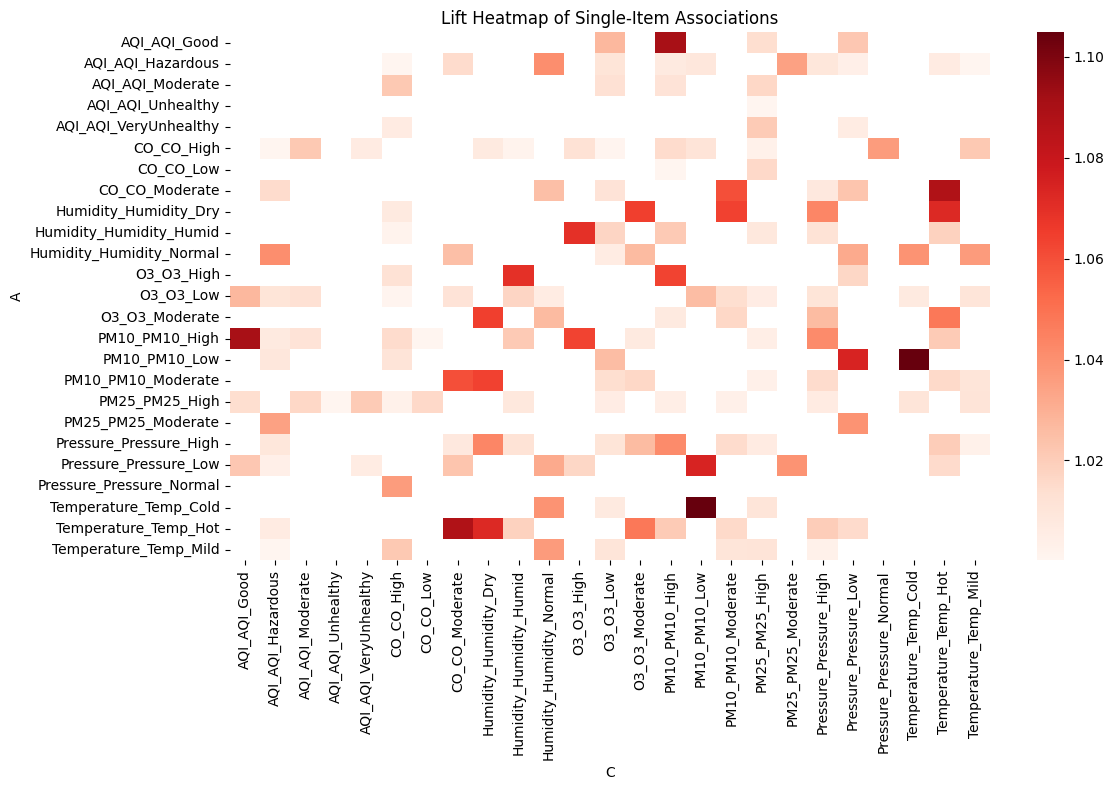

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

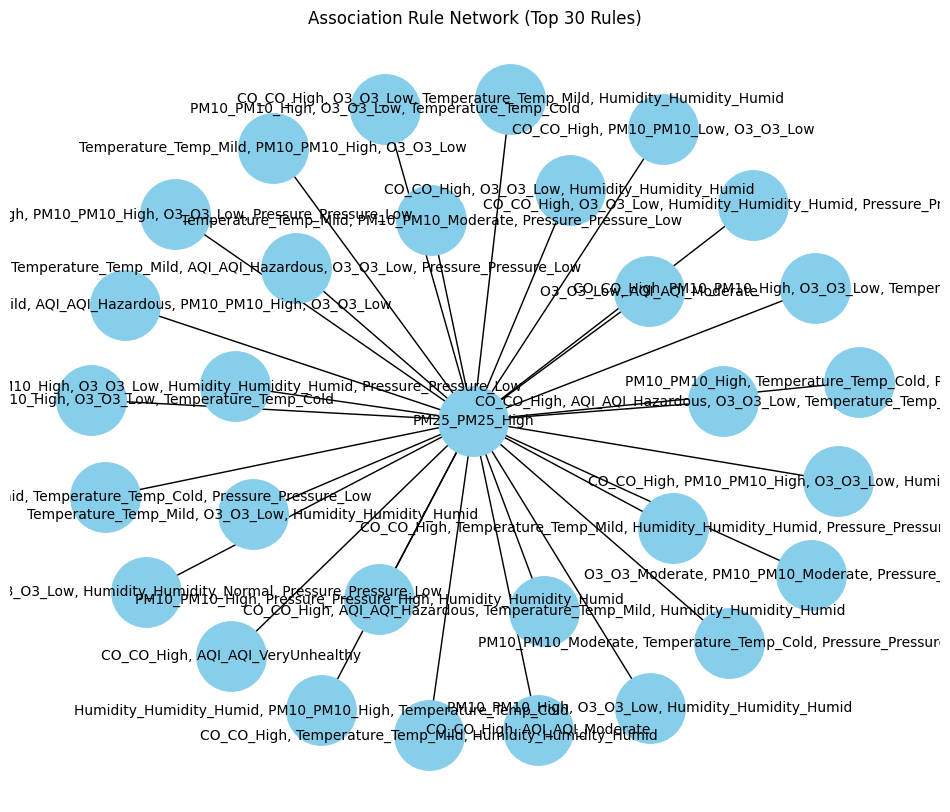

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Day rules saved: 5328


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Night rules saved: 4996

Strong High-Impact Rules:
 Empty DataFrame
Columns: [antecedents, consequents, support, confidence, lift]
Index: []


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import networkx as nx
from mlxtend.frequent_patterns import apriori, association_rules
df = pd.read_csv("AirQualityData.csv")

# ----------------------------------------------------------------------
def bin_aqi(x):
    if x <= 50: return "AQI_Good"
    elif x <= 100: return "AQI_Moderate"
    elif x <= 150: return "AQI_Unhealthy"
    elif x <= 200: return "AQI_VeryUnhealthy"
    else: return "AQI_Hazardous"

def bin_co(x):
    if x < 1: return "CO_Low"
    elif x < 3: return "CO_Moderate"
    else: return "CO_High"

def bin_pm25(x):
    if x < 12: return "PM25_Low"
    elif x < 35: return "PM25_Moderate"
    else: return "PM25_High"

def bin_pm10(x):
    if x < 50: return "PM10_Low"
    elif x < 150: return "PM10_Moderate"
    else: return "PM10_High"

def bin_o3(x):
    if x < 100: return "O3_Low"
    elif x < 160: return "O3_Moderate"
    else: return "O3_High"

def bin_temp(x):
    if x < 10: return "Temp_Cold"
    elif x < 25: return "Temp_Mild"
    else: return "Temp_Hot"

def bin_hum(x):
    if x < 30: return "Humidity_Dry"
    elif x < 60: return "Humidity_Normal"
    else: return "Humidity_Humid"

def bin_pressure(x):
    if x < 1010: return "Pressure_Low"
    elif x < 1020: return "Pressure_Normal"
    else: return "Pressure_High"

# Apply binning to key columns
binned = pd.DataFrame({
    'CO': df['CO(GT)'].apply(bin_co),
    'PM25': df['PM2.5'].apply(bin_pm25),
    'PM10': df['PM10'].apply(bin_pm10),
    'O3': df['O3(GT)'].apply(bin_o3),
    'Temperature': df['Temperature'].apply(bin_temp),
    'Humidity': df['Humidity'].apply(bin_hum),
    'Pressure': df['Pressure'].apply(bin_pressure),
    'AQI': df['AirQualityIndex'].apply(bin_aqi)
})

# ----------------------------------------------------------------------
# 3️⃣ Apriori Association Rule Mining
# ----------------------------------------------------------------------
transactions = pd.get_dummies(binned)
frequent_itemsets = apriori(transactions, min_support=0.05, use_colnames=True)
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)
rules = rules.sort_values(['confidence','lift'], ascending=False)

# Save all rules
rules.to_csv("AirQuality_Association_Rules.csv", index=False)
print("Total rules discovered:", len(rules))
print("Top 10 rules:\n", rules.head(10))

# ----------------------------------------------------------------------
# 4️⃣ Lift Heatmap (Pairwise Associations)
# ----------------------------------------------------------------------
# Build a matrix of lift for top pairs
pairs = []
for _, row in rules.iterrows():
    if len(row['antecedents']) == 1 and len(row['consequents']) == 1:
        a = list(row['antecedents'])[0]
        c = list(row['consequents'])[0]
        pairs.append((a, c, row['lift']))

if pairs:
    pair_df = pd.DataFrame(pairs, columns=["A","C","Lift"])
    heatmap_df = pair_df.pivot_table(index="A", columns="C", values="Lift")
    plt.figure(figsize=(12,8))
    sns.heatmap(heatmap_df, cmap="Reds", annot=False)
    plt.title("Lift Heatmap of Single-Item Associations")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

# ----------------------------------------------------------------------
# 5️⃣ Network Graph of Top Rules
# ----------------------------------------------------------------------
G = nx.Graph()
top_rules = rules.head(30)   # adjust number as needed
for _, r in top_rules.iterrows():
    ant = ', '.join(r['antecedents'])
    con = ', '.join(r['consequents'])
    G.add_edge(ant, con, weight=r['lift'], confidence=r['confidence'])

plt.figure(figsize=(12,10))
pos = nx.spring_layout(G, k=0.5, seed=42)
nx.draw_networkx_nodes(G, pos, node_color="skyblue", node_size=2500)
nx.draw_networkx_labels(G, pos, font_size=10)
edges = nx.draw_networkx_edges(G, pos, width=[d['weight'] for _,_,d in G.edges(data=True)])
plt.title("Association Rule Network (Top 30 Rules)")
plt.axis('off')
plt.show()

# ----------------------------------------------------------------------
# 6️⃣ Temporal Segmentation (Day vs Night)
# ----------------------------------------------------------------------
if 'Hour' in df.columns:
    df['Period'] = np.where(df['Hour'].between(6,18), "Day", "Night")

    for period in ['Day','Night']:
        segment = df[df['Period']==period]
        if len(segment) > 0:
            seg_binned = pd.DataFrame({
                'CO': segment['CO(GT)'].apply(bin_co),
                'PM25': segment['PM2.5'].apply(bin_pm25),
                'PM10': segment['PM10'].apply(bin_pm10),
                'O3': segment['O3(GT)'].apply(bin_o3),
                'Temperature': segment['Temperature'].apply(bin_temp),
                'Humidity': segment['Humidity'].apply(bin_hum),
                'Pressure': segment['Pressure'].apply(bin_pressure),
                'AQI': segment['AirQualityIndex'].apply(bin_aqi)
            })
            trans = pd.get_dummies(seg_binned)
            fi = apriori(trans, min_support=0.05, use_colnames=True)
            r_seg = association_rules(fi, metric="lift", min_threshold=1.0)
            r_seg = r_seg.sort_values(['confidence','lift'], ascending=False)
            r_seg.to_csv(f"AssociationRules_{period}.csv", index=False)
            print(f"{period} rules saved:", len(r_seg))

strong_rules = rules[(rules['confidence'] > 0.6) & (rules['lift'] > 1.5)]
print("\nStrong High-Impact Rules:\n", strong_rules[['antecedents','consequents','support','confidence','lift']])


In [4]:
# Source: https://www.kaggle.com/datasets/khushikyad001/air-quality-data?resource=download

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag